In [1]:
# =====================================================
# APPLICATION 2: USERNAME VALIDATION SYSTEM
# FINITE AUTOMATA IMPLEMENTATION
# =====================================================

# STEP 1: Define DFA components

# Input Alphabet
letters = "abcdefghijklmnopqrstuvwxyz"
digits = "0123456789"
allowed_symbols = letters + digits + "_"

# Set of States
states = ['q0', 'q1', 'q2', 'q3', 'q4',
          'q5', 'q6', 'q7', 'q8', 'qd']

# Initial State
initial_state = 'q0'

# Final States (username length 3 to 8)
final_states = ['q3', 'q4', 'q5', 'q6', 'q7', 'q8']


# STEP 2: Define the Transition Function

def transition(state, symbol):

    # Dead state
    if state == 'qd':
        return 'qd'

    # First character must be a lowercase letter
    if state == 'q0':
        if symbol in letters:
            return 'q1'
        else:
            return 'qd'

    # Remaining characters
    if state in states[1:9]:

        if symbol in allowed_symbols:

            state_number = int(state[1])

            if state_number < 8:
                return 'q' + str(state_number + 1)

            else:
                return 'qd'

        else:
            return 'qd'

    return 'qd'


# STEP 3: Implement DFA Processing

def username_dfa(username):

    current_state = initial_state

    print("\nInput Username:", username)
    print("Initial State:", current_state)

    for symbol in username:

        next_state = transition(current_state, symbol)

        print("Input Symbol:", symbol,
              "| Current State:", current_state,
              "| Next State:", next_state)

        current_state = next_state

    # STEP 4: Check Final State

    if current_state in final_states:
        print("Final State:", current_state)
        print("Result: ACCEPTED")
        return "Accepted"

    else:
        print("Final State:", current_state)
        print("Result: REJECTED")
        return "Rejected"


# STEP 5: Test Multiple Inputs

test_cases = [
    "siddhi",
    "abc_12",
    "hello1",
    "1hello",
    "ab",
    "hello@",
    "abcdefghij"
]

print("USERNAME VALIDATION - TEST RESULTS")
print("=" * 45)

for username in test_cases:
    username_dfa(username)
    print("-" * 45)


# STEP 6: Accept Input From User

user_username = input("\nEnter your username: ")

username_dfa(user_username)

USERNAME VALIDATION - TEST RESULTS

Input Username: siddhi
Initial State: q0
Input Symbol: s | Current State: q0 | Next State: q1
Input Symbol: i | Current State: q1 | Next State: q2
Input Symbol: d | Current State: q2 | Next State: q3
Input Symbol: d | Current State: q3 | Next State: q4
Input Symbol: h | Current State: q4 | Next State: q5
Input Symbol: i | Current State: q5 | Next State: q6
Final State: q6
Result: ACCEPTED
---------------------------------------------

Input Username: abc_12
Initial State: q0
Input Symbol: a | Current State: q0 | Next State: q1
Input Symbol: b | Current State: q1 | Next State: q2
Input Symbol: c | Current State: q2 | Next State: q3
Input Symbol: _ | Current State: q3 | Next State: q4
Input Symbol: 1 | Current State: q4 | Next State: q5
Input Symbol: 2 | Current State: q5 | Next State: q6
Final State: q6
Result: ACCEPTED
---------------------------------------------

Input Username: hello1
Initial State: q0
Input Symbol: h | Current State: q0 | Next St

'Rejected'

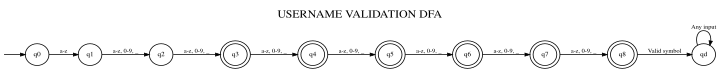

In [2]:
# =====================================================
# USERNAME VALIDATION - DFA STATE DIAGRAM
# =====================================================

from graphviz import Digraph

dot = Digraph('Username_DFA')

# Compact diagram settings
dot.attr(
    rankdir='LR',
    size='10,3!',
    ratio='compress',
    nodesep='0.25',
    ranksep='0.35',
    margin='0.1',
    label='USERNAME VALIDATION DFA',
    labelloc='t',
    fontsize='15'
)

dot.attr(
    'node',
    shape='circle',
    width='0.42',
    height='0.42',
    fixedsize='true',
    fontsize='9'
)

dot.attr(
    'edge',
    fontsize='8',
    arrowsize='0.6'
)

# STEP 1: Create DFA states

dot.node('start', label='', shape='none', width='0')

states = ['q0', 'q1', 'q2', 'q3', 'q4',
          'q5', 'q6', 'q7', 'q8', 'qd']

final_states = ['q3', 'q4', 'q5', 'q6', 'q7', 'q8']

for state in states:
    if state in final_states:
        dot.node(state, shape='doublecircle')
    else:
        dot.node(state)

# STEP 2: Set initial state

dot.edge('start', 'q0')

# STEP 3: Add transitions

dot.edge('q0', 'q1', label='a-z')

for i in range(1, 8):
    dot.edge(
        'q' + str(i),
        'q' + str(i+1),
        label='a-z, 0-9, _'
    )

# STEP 4: Add dead state transitions

dot.edge('q8', 'qd', label='Valid symbol')
dot.edge('qd', 'qd', label='Any input')

# STEP 5: Display diagram

dot